In [1]:
import os, glob
os.makedirs("/content/sales", exist_ok=True); os.chdir("/content/sales")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 1. Load dataset (Kaggle: bumba5341/advertisingcsv)
try:
    import kagglehub
    folder = kagglehub.dataset_download("bumba5341/advertisingcsv")
    CSV_PATH = glob.glob(os.path.join(folder, "*.csv"))[0]
except Exception as e:
    print("kagglehub failed, using local Advertising.csv:", e)
    CSV_PATH = "Advertising.csv"
print("Using file:", CSV_PATH)
df = pd.read_csv(CSV_PATH)
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed")], errors="ignore")
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)
print(df.head(), "\n")
print(df.describe(), "\n")
print("Missing values:\n", df.isnull().sum(), "\n")
df = df.drop_duplicates().dropna()
target = next(c for c in df.columns if c.lower() == "sales")
features = [c for c in df.columns if c != target]

Using Colab cache for faster access to the 'advertisingcsv' dataset.
Using file: /kaggle/input/advertisingcsv/Advertising.csv
Shape: (200, 4)
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9 

               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000 

Missing values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64 



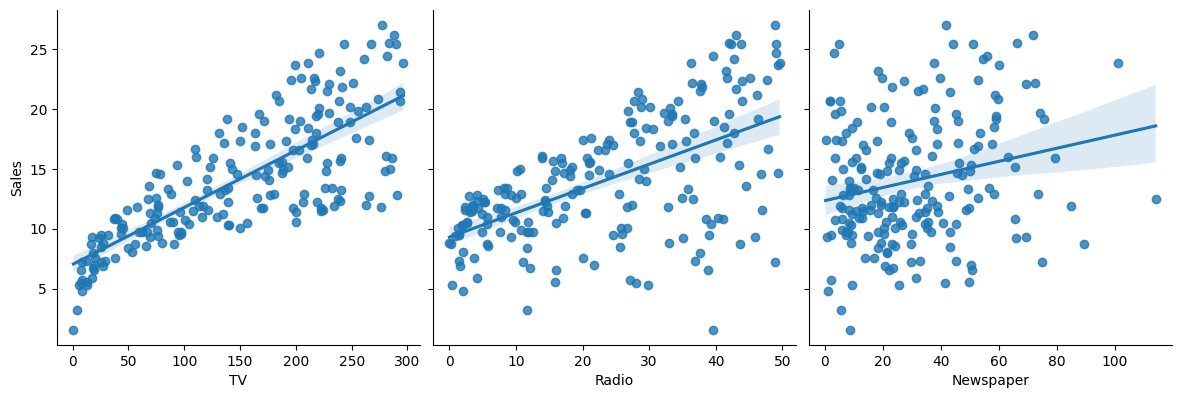

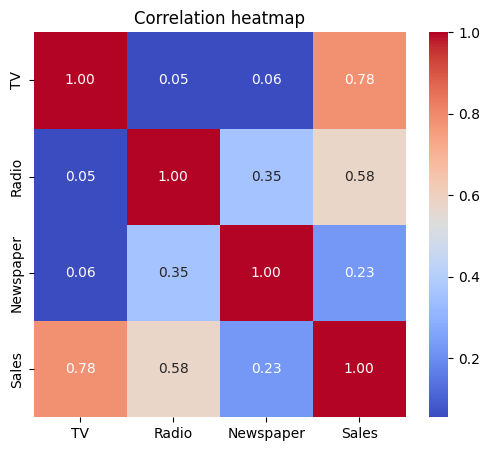

Correlation with Sales:
 TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64 



In [3]:
# 2. EDA
sns.pairplot(df, x_vars=features, y_vars=target, height=4, kind="reg")
plt.savefig("ad_vs_sales.png", dpi=120, bbox_inches="tight"); plt.show()
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.savefig("correlation_heatmap.png", dpi=120, bbox_inches="tight"); plt.show()
print("Correlation with Sales:\n", df.corr()[target].drop(target).sort_values(ascending=False), "\n")


In [4]:
# 3. Split
X, y = df[features], df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

             Model    CV R2  Test R2      MAE     RMSE
Polynomial (deg 2) 0.975637 0.987782 0.484783 0.621014
 Gradient Boosting 0.969725 0.983127 0.618742 0.729782
     Random Forest 0.970126 0.982635 0.613075 0.740335
 Linear Regression 0.859488 0.899438 1.460757 1.781600
             Ridge 0.859656 0.898803 1.464301 1.787220 

Best model: Polynomial (deg 2)


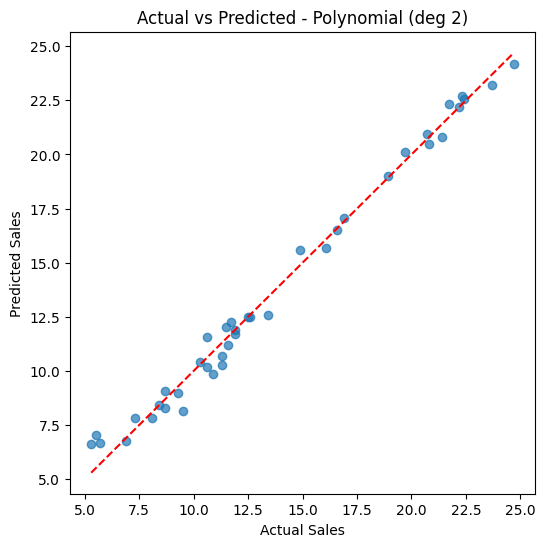

In [5]:
# 4. Models
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Polynomial (deg 2)": make_pipeline(PolynomialFeatures(2), StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows, fitted = [], {}
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append([name, cv, r2_score(y_test, p), mean_absolute_error(y_test, p),
                 np.sqrt(mean_squared_error(y_test, p))])
    fitted[name] = m
res = pd.DataFrame(rows, columns=["Model", "CV R2", "Test R2", "MAE", "RMSE"]).sort_values("Test R2", ascending=False)
print(res.to_string(index=False), "\n")
best_name = res.iloc[0]["Model"]
best = fitted[best_name]
p = best.predict(X_test)
print("Best model:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, p, alpha=0.7)
lims = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual Sales"); plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted - {best_name}")
plt.savefig("actual_vs_predicted.png", dpi=120, bbox_inches="tight"); plt.show()


In [6]:
# 5. Business insight
lin = LinearRegression().fit(X, y)
print("\nImpact of +1 unit ad spend on Sales (others constant):")
for f, c in zip(features, lin.coef_):
    print(f"  {f:<10}: {c:+.4f}")
base = X.mean().to_frame().T
print("\nWhat-if (increase one channel by 10 units):")
for f in features:
    up = base.copy(); up[f] += 10
    print(f"  +10 on {f:<10} -> sales change {best.predict(up)[0] - best.predict(base)[0]:+.2f}")


Impact of +1 unit ad spend on Sales (others constant):
  TV        : +0.0458
  Radio     : +0.1885
  Newspaper : -0.0010

What-if (increase one channel by 10 units):
  +10 on TV         -> sales change +0.43
  +10 on Radio      -> sales change +1.91
  +10 on Newspaper  -> sales change +0.04
